# Data Analysis - (Part 5) - CLASS EXERCISE SOLUTIONS

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from analyticskit import *

pd.options.display.float_format = '{:,.2f}'.format # Display option to include 2 decimal places on all floats
pd.set_option('display.max_columns', None) # Display option to show all columns
pd.set_option('display.max_rows', None) # Display option to show all rows

# I'm also importing this package to ignore warnings that we don't need to worry about in this class
import warnings
warnings.filterwarnings("ignore")

In [2]:
data = pd.read_csv('compustat.csv',parse_dates=['datadate'])
sic_indnames = pd.read_csv('sic_indnames.csv')
data = pd.merge(data,sic_indnames,on='sic',how='left')

#### Exercise 1

1. Create a DataFrame called `computers` using the `data` DataFrame. The Computers industry has an `sic` code equal to `3571`. 

In [3]:
# 1
computers = data[data.sic==3571]

2. Create a scatter plot that plots `at` on the x-axis and `mktcap` on the y-axis. Set `alpha` equal to 0.7.

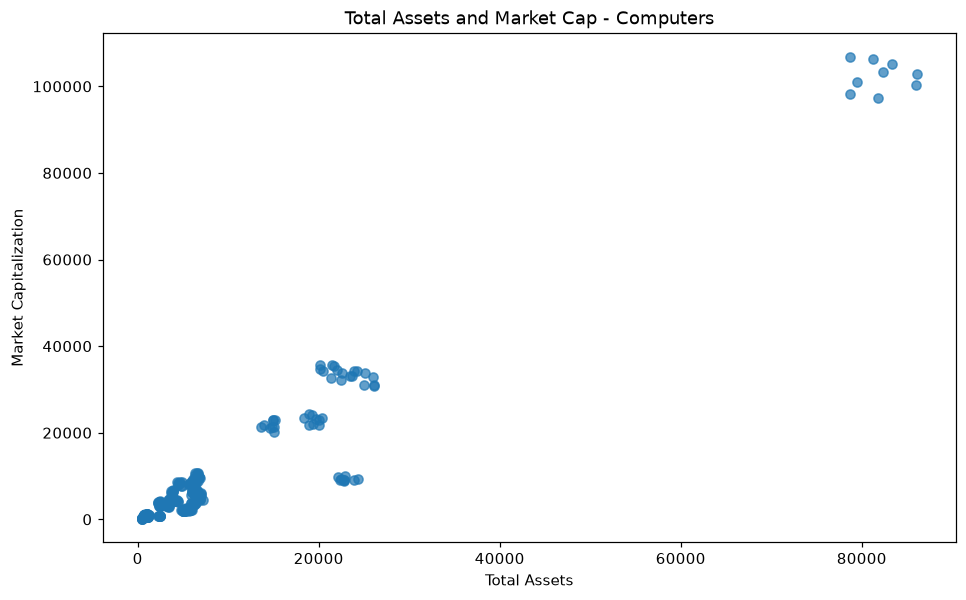

In [4]:
# 2

plt.figure(figsize=(10,6))
plt.scatter(computers['at'],computers['mktcap'],alpha=.7)
plt.xlabel('Total Assets')
plt.ylabel('Market Capitalization')
plt.title('Total Assets and Market Cap - Computers')
plt.show()

3. What do you notice about the relation between total assets (`at`) and market capitalization (`mktcap`) for the Computers industry? Why do you think we observe a difference in these graphs for the Natural Gas and Computers industries?

In [5]:
# 3

# There is much more variation in the relation between total assets and market cap within the Computers industry
# than we found in the Natural Gas industry. This is likely due to companies in the Computers industry that have
# great market potential, but do not currently have a large number of assets. For example, companies investing heavily
# in R&D may not currently have a large number of assets, but the market prices in a company's potential.

# Let's take a look at a few companies with low total assets and high market cap:

computers[(computers['at'] < 30000) & (computers.mktcap > 120000)]

# We find that these companies are Computer companies in the early 2000s when computers were uncommon, and we still
# had a lot to learn!

Empty DataFrame
Columns: [gvkey, datadate, sic, at, lt, mktcap, industry]
Index: []

#### Exercise 2

The code below creates a new DataFrame called `industry_subset` containing all observations from `data` where `sic` is in the list: [6020,4924,3571,1040,5812,3760,5411].

In [6]:
industry_subset = data[data['sic'].isin([6020,4924,3571,1040,5812,3760,5411])]
industry_subset.head()

    gvkey   datadate   sic       at       lt   mktcap   industry
0  100037 2016-12-31  3571 3,472.46 1,521.44 2,951.75  Computers
1  100037 2017-12-31  3571 3,301.86 1,504.48 3,244.12  Computers
2  100037 2018-12-31  3571 3,386.20 1,516.91 2,943.84  Computers
3  100037 2019-12-31  3571 3,371.30 1,427.69 3,069.12  Computers
4  100037 2020-12-31  3571 3,244.84 1,520.29 2,978.41  Computers

1. Create a new column in the `industry_subset` DataFrame called `leverage` equal to `lt`/`at`. Print the first 5 rows to ensure the column was properly created.

In [7]:
# 1

industry_subset['leverage'] = industry_subset['lt']/industry_subset['at']
industry_subset.head()

    gvkey   datadate   sic       at       lt   mktcap   industry  leverage
0  100037 2016-12-31  3571 3,472.46 1,521.44 2,951.75  Computers      0.44
1  100037 2017-12-31  3571 3,301.86 1,504.48 3,244.12  Computers      0.46
2  100037 2018-12-31  3571 3,386.20 1,516.91 2,943.84  Computers      0.45
3  100037 2019-12-31  3571 3,371.30 1,427.69 3,069.12  Computers      0.42
4  100037 2020-12-31  3571 3,244.84 1,520.29 2,978.41  Computers      0.47

2. Use the `groupby` and `median` methods to create a DataFrame called `industry_medians` containing the median value of `leverage` for each `industry` name in the `industry_subset` DataFrame.

In [8]:
# 2

industry_medians = industry_subset.groupby(['industry'])['leverage'].median().reset_index()
industry_medians

                             industry  leverage
0                               Banks      0.85
1                           Computers      0.50
2                       Eating Places      0.47
3                Gold and Silver Ores      0.40
4                      Grocery Stores      0.48
5  Guided Missiles and Space Vehicles      0.42
6            Natural Gas Distribution      0.42

3. Create a horizontal bar chart with  `industry` as the categories and the median `leverage` as the values. Add a title. Include `'Leverage'` as the x-axis label and `'Industry'` as the y-axis label. Which industry appears to have the highest leverage? Can you think of any reasons why this might be the case?

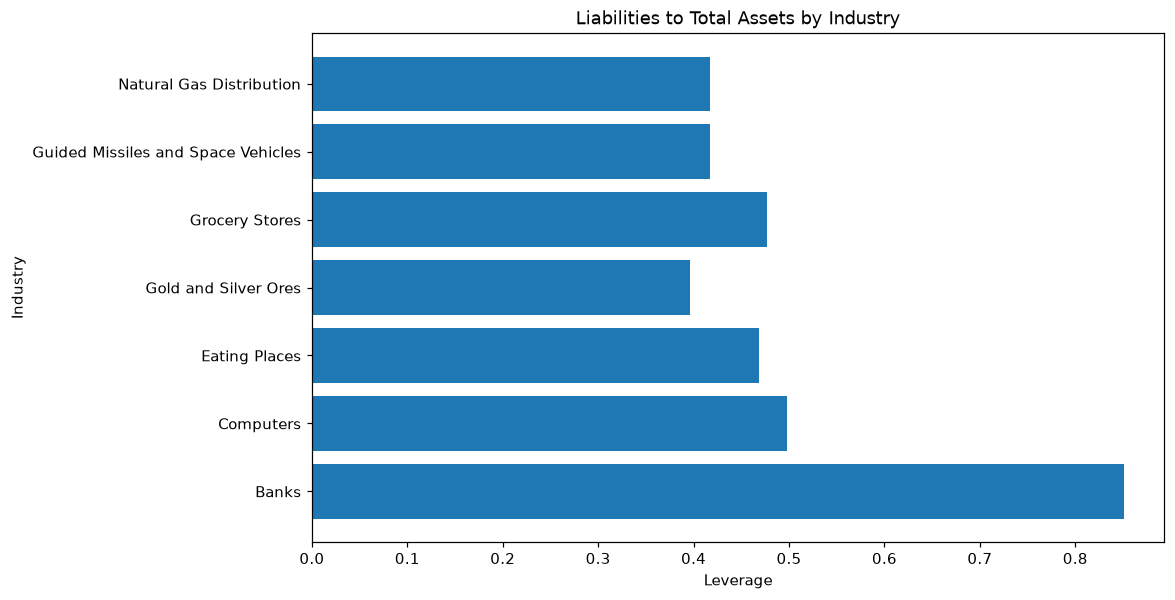

In [9]:
# 3

plt.figure(figsize=(10,6))
plt.barh(industry_medians['industry'], industry_medians['leverage'])
plt.title('Liabilities to Total Assets by Industry')
plt.xlabel('Leverage')
plt.ylabel('Industry')
plt.show()

# Banks tend to have higher leverage because they borrow capital (e.g., from you and me when we deposit our money!)
# in order to lend to customers (e.g., you and me when we want to buy a car, home, etc.).

#### Exercise 3

1. View the summary statistics for the `mktcap` column in the `data` DataFrame. What do you notice about the tails of the distribution?

In [10]:
# 1

data[['mktcap']].describe([.01,.05,.1,.25,.5,.75,.9,.95,.99])

# The maximum value is huge compared to the 99th and 95th percentiles.

            mktcap
count    10,647.00
mean      9,337.75
std      61,800.46
min          42.36
1%          152.33
5%          426.90
10%         785.27
25%       1,774.76
50%       3,680.76
75%       6,785.80
90%      11,099.66
95%      24,206.51
99%     124,548.15
max   3,380,448.21

2. Create a new variable called `mktcap_w` in the `data` DataFrame equal to the `mktcap` variable winsorized at the 5th and 95th percentiles. 

    Create a new variable called `mktcap_t` in the `data` DataFrame equal to the `mktcap` variable truncated at the 5th and 95th percentiles.

In [11]:
# 2

# Winsorize
data['mktcap_w'] = winsorize(data['mktcap'], lower_percentile=0.05, upper_percentile=0.95)

# Truncate
data['mktcap_t'] = truncate(data['mktcap'], lower_percentile=0.05, upper_percentile=0.95)

# View the data
data[['mktcap', 'mktcap_w','mktcap_t']].describe([.01,.05,.1,.25,.5,.75,.9,.95,.99])

            mktcap  mktcap_w  mktcap_t
count    10,647.00 10,647.00  9,581.00
mean      9,337.75  5,479.64  4,718.94
std      61,800.46  5,747.91  3,899.25
min          42.36    426.90    427.20
1%          152.33    426.90    484.83
5%          426.90    426.99    750.42
10%         785.27    785.27  1,016.47
25%       1,774.76  1,774.76  1,937.36
50%       3,680.76  3,680.76  3,680.76
75%       6,785.80  6,785.80  6,395.46
90%      11,099.66 11,099.66  9,292.07
95%      24,206.51 24,205.81 11,458.81
99%     124,548.15 24,206.51 20,894.25
max   3,380,448.21 24,206.51 24,204.18

3. Plot a histogram using either `mktcap_w` or `mktcap_t` (you can choose, or try both). Use the following options:
    1. Figure size: 10 x 6
    2. Number of bins: 20
    3. title: "Distribution of Market Capitalization"
    4. x-axis label: "Market Capitalization"
    5. y-axis label: "Frequency"
    
    What do you notice about the number of firms with large vs. small market cap?

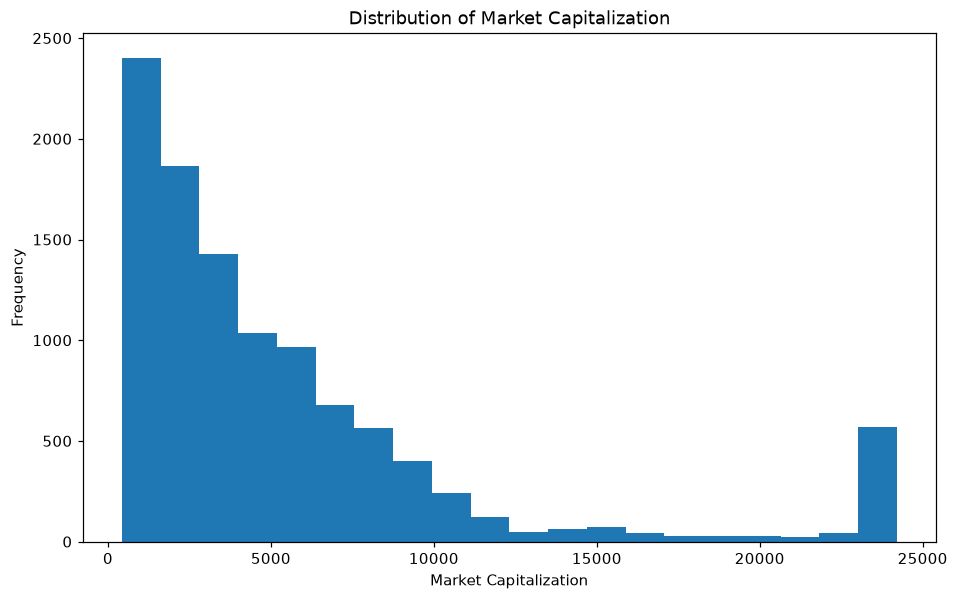

In [12]:
# 3

plt.figure(figsize=(10,6))
plt.hist(data['mktcap_w'],bins=20)
plt.title('Distribution of Market Capitalization')
plt.xlabel('Market Capitalization')
plt.ylabel('Frequency')
plt.show()

# Most firms are small. Only a few firms have market capitalization over $14 billion.